# Notebook 3: Exploratory analysis, statistics, sampling and hypothesis tests

**Inputs:** `data/focus_crops_clean.csv` and `data/weekly_panel.csv` (made by Notebook 2)
**Outputs:**
- `data/market_month.csv`: one price per market per month, used by the later notebooks
- `data/hypothesis_results.csv`: every test result in one table (for the report)

**Research question answered here (RQ1):** which crop has the more volatile and seasonal price, how does this differ
by district, and does storing after harvest pay? Each section below answers one part of the sell-or-store decision.

| Section | Question for a farmer | Kind of analysis |
| --- | --- | --- |
| 1 | What data do we have? | Overview, coverage over time |
| 2 | What do prices look like? | Univariate: distribution, skewness, normality |
| 3 | How have prices moved over 23 years? | Temporal: long-run trend, instability index |
| 4 | When are prices low and high, and is that timing reliable? | Temporal: seasonality |
| 5 | If I store after harvest, how much do I gain, and how often do I lose? | Bivariate: gain vs months stored |
| 6 | How risky is each crop? | Subgroup: volatility, onion vs maize, by district |
| 7 | Where should I sell? | Geographical: price premium by district |
| 8 | Do mandis move together? | Multivariate: correlation between markets |
| 9 | If we can only watch 10 mandis, how should we pick them? | Sampling: random, stratified, systematic, bootstrap |
| 10 | Which findings are statistically real? | Hypothesis tests H1 to H5 |
| 11 | What this means for the next notebooks | Summary |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

CLEAN_FILE = "../data/focus_crops_clean.csv"
PANEL_FILE = "../data/weekly_panel.csv"
SEED = 42
ALPHA = 0.05

BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
CROP_COLOR = {"Maize": BLUE, "Onion": ORANGE}
CROPS = ["Onion", "Maize"]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
DIVERGING = LinearSegmentedColormap.from_list("cheap_dear", [BLUE, "#f7f6f2", ORANGE])   # blue = cheap, orange = dear
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "font.size": 10,
})
pd.set_option("display.width", 160)

# Karnataka's four revenue divisions, used to group districts into regions
DIVISION = {
    "Bangalore": "Bengaluru", "Kolar": "Bengaluru", "Tumkur": "Bengaluru", "Chitradurga": "Bengaluru",
    "Davangere": "Bengaluru", "Shimoga": "Bengaluru",
    "Mysore": "Mysuru", "Mandya": "Mysuru", "Chamrajnagar": "Mysuru", "Hassan": "Mysuru",
    "Madikeri(Kodagu)": "Mysuru", "Chikmagalur": "Mysuru", "Mangalore(Dakshin Kannad)": "Mysuru", "Udupi": "Mysuru",
    "Belgaum": "Belagavi", "Bagalkot": "Belagavi", "Bijapur": "Belagavi", "Dharwad": "Belagavi",
    "Gadag": "Belagavi", "Haveri": "Belagavi", "Karwar(Uttar Kannad)": "Belagavi",
    "Kalburgi": "Kalaburagi", "Bidar": "Kalaburagi", "Yadgiri": "Kalaburagi", "Raichur": "Kalaburagi",
    "Koppal": "Kalaburagi", "Bellary": "Kalaburagi",
}
DIV_ORDER = ["Bengaluru", "Mysuru", "Belagavi", "Kalaburagi"]

## 0. Load the data and build the market-month table

Markets report at different rates: some every day, others once a week. If every record counted equally, busy markets
would dominate every statistic. So most of the analysis uses **one price per market per month** (the median of that
month's records). This also reduces the dependence between records from the same market in the same week.

Two derived measures are used throughout:
- **Seasonal relative price** = a month's price divided by that market's average for the year. 1.20 means 20% above
  the market's own yearly average. Only market-years with at least 10 months of data are used, so the yearly average
  is fair.
- **Premium** = a market's price divided by the statewide median price that month. 1.10 means this market paid 10%
  more than the typical Karnataka market that month.

Both are ratios, so general inflation cancels out.

In [2]:
clean = pd.read_csv(CLEAN_FILE, parse_dates=["date"])
panel = pd.read_csv(PANEL_FILE, parse_dates=["week"])
clean["division"] = clean["district"].map(DIVISION)
print("Districts without a division:", clean.loc[clean["division"].isna(), "district"].unique())

clean["ym"] = clean["date"].dt.to_period("M")
mm = (clean.groupby(["commodity", "division", "district", "market", "ym"])["modal_price"]
            .median().rename("price").reset_index())
mm["year"], mm["month"] = mm["ym"].dt.year, mm["ym"].dt.month
mm["state_median"] = mm.groupby(["commodity", "ym"])["price"].transform("median")
mm["premium"] = mm["price"] / mm["state_median"]

months_in_year = mm.groupby(["commodity", "market", "year"])["price"].transform("size")
mm["full_year"] = months_in_year >= 10
year_mean = mm.groupby(["commodity", "market", "year"])["price"].transform("mean")
mm["seasonal_rel"] = (mm["price"] / year_mean).where(mm["full_year"])

print(f"Market-months: {len(mm):,}  |  market-years with >= 10 months: "
      f"{mm[mm['full_year']].groupby(['commodity', 'market', 'year']).ngroups:,}")
mm.head()

Districts without a division: <ArrowStringArray>
[]
Length: 0, dtype: str
Market-months: 25,707  |  market-years with >= 10 months: 1,524


,commodity,division,district,market,ym,price,year,month,state_median,premium,full_year,seasonal_rel
0,Maize,Belagavi,Bagalkot,Badami,2003-01,500.0,2003,1,500.0,1.000000,True,0.980392
1,Maize,Belagavi,Bagalkot,Badami,2003-02,500.0,2003,2,525.0,0.952381,True,0.980392
2,Maize,Belagavi,Bagalkot,Badami,2003-03,500.0,2003,3,530.0,0.943396,True,0.980392
3,Maize,Belagavi,Bagalkot,Badami,2003-04,500.0,2003,4,530.0,0.943396,True,0.980392
4,Maize,Belagavi,Bagalkot,Badami,2003-05,515.0,2003,5,530.0,0.971698,True,1.009804


## 1. What data do we have?

,price records,market-months,markets,districts,first date,last date,median price (Rs/quintal)
commodity,,,,,,,
Onion,90011,8020,108,27,2003-01-01,2026-04-13,1000.0
Maize,163822,17687,141,26,2003-01-01,2026-04-13,1200.0


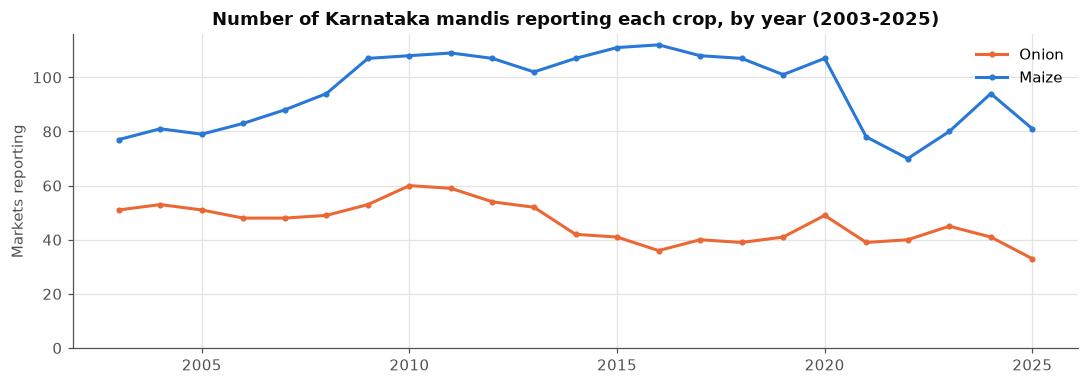

In [3]:
overview = pd.DataFrame({
    "price records": clean.groupby("commodity").size(),
    "market-months": mm.groupby("commodity").size(),
    "markets": clean.groupby("commodity")["market"].nunique(),
    "districts": clean.groupby("commodity")["district"].nunique(),
    "first date": clean.groupby("commodity")["date"].min().dt.date,
    "last date": clean.groupby("commodity")["date"].max().dt.date,
    "median price (Rs/quintal)": clean.groupby("commodity")["modal_price"].median(),
}).loc[CROPS]
display(overview)

active = mm[mm["year"] <= 2025].groupby(["commodity", "year"])["market"].nunique().unstack(0)
fig, ax = plt.subplots(figsize=(10, 3.6))
for crop in CROPS:
    ax.plot(active.index, active[crop], color=CROP_COLOR[crop], linewidth=2, marker="o", markersize=3, label=crop)
ax.set_ylabel("Markets reporting")
ax.set_title("Number of Karnataka mandis reporting each crop, by year (2003-2025)")
ax.set_ylim(0, None)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Reading the chart.** Maize is reported by about twice as many mandis as onion, because maize is grown across
north and central Karnataka while onion trading is concentrated in fewer markets. Coverage changes over time: onion
fell from about 55 markets to about 40 after 2013, and maize dipped in 2021-2022. A plain statewide average would
mix real price changes with changes in which markets report, so the analysis mostly uses ratios **within** each
market (Section 0). 2026 (January to mid-April only) is left out of all yearly statistics.

## 2. What do prices look like? (univariate)

In [4]:
def describe_prices(s):
    return pd.Series({
        "mean": s.mean(), "median": s.median(), "std": s.std(), "CV %": 100 * s.std() / s.mean(),
        "skewness": stats.skew(s), "excess kurtosis": stats.kurtosis(s),
        "min": s.min(), "Q1": s.quantile(0.25), "Q3": s.quantile(0.75), "max": s.max(),
    })

desc = pd.concat({crop: describe_prices(mm.loc[mm["commodity"] == crop, "price"]) for crop in CROPS}, axis=1)
desc_log = pd.concat({crop: describe_prices(np.log(mm.loc[mm["commodity"] == crop, "price"])) for crop in CROPS}, axis=1)
print("Monthly market prices, Rs per quintal:")
display(desc.round(2))
print("Same, on the log scale:")
display(desc_log.loc[["skewness", "excess kurtosis"]].round(2))

Monthly market prices, Rs per quintal:


,Onion,Maize
mean,1249.36,1241.51
median,1000.00,1200.00
std,965.88,552.10
CV %,77.31,44.47
skewness,2.23,0.74
excess kurtosis,9.38,0.82
min,120.00,200.00
Q1,567.38,800.00
Q3,1650.00,1520.00
max,11100.00,5600.00


Same, on the log scale:


,Onion,Maize
skewness,0.06,-0.27
excess kurtosis,-0.51,-0.68


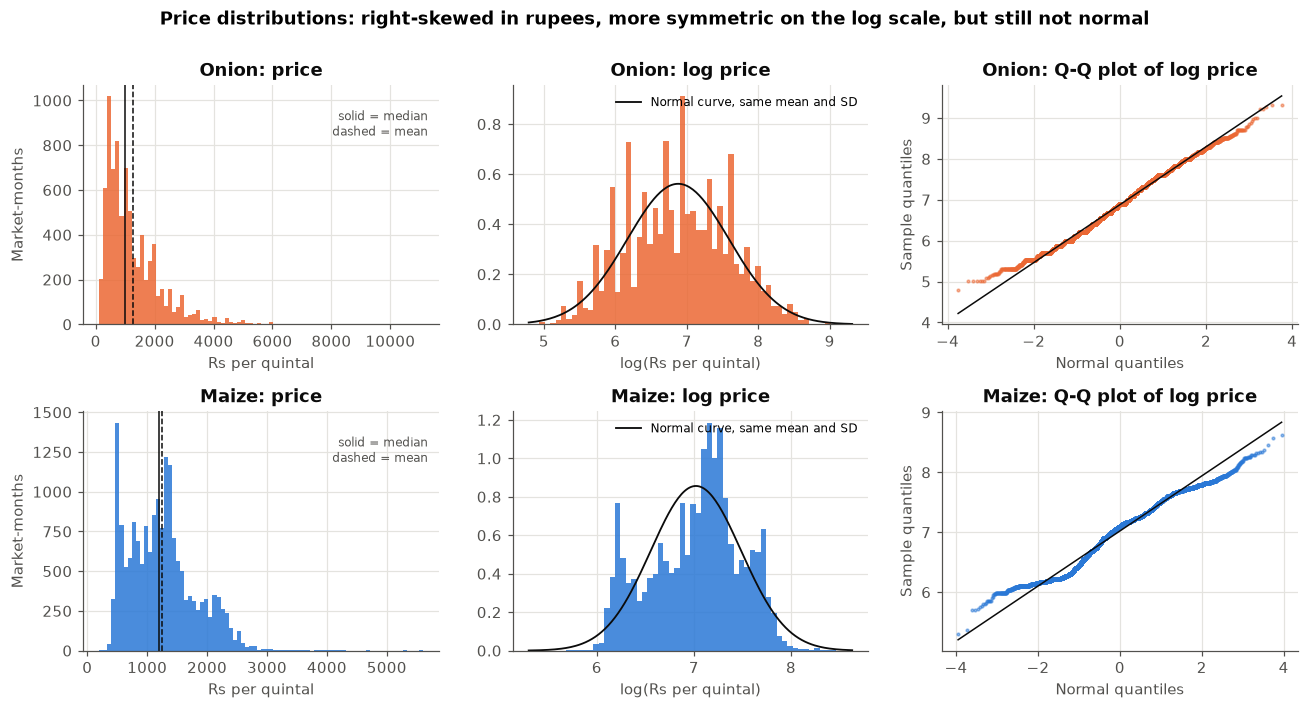

,crop,data,n,D'Agostino K2,p-value
0,Onion,all market-months,8020,169.8,1.322882e-37
1,Onion,random sample of 500,500,23.7,7.094170e-06
2,Maize,all market-months,17687,1050.5,7.599755e-229
3,Maize,random sample of 500,500,31.4,1.492136e-07


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
for row, crop in enumerate(CROPS):
    p = mm.loc[mm["commodity"] == crop, "price"]
    lp = np.log(p)
    color = CROP_COLOR[crop]

    ax = axes[row, 0]
    ax.hist(p, bins=80, color=color, alpha=0.85)
    ax.axvline(p.mean(), color=INK, linewidth=1, linestyle="--"); ax.axvline(p.median(), color=INK, linewidth=1)
    ax.set_title(f"{crop}: price"); ax.set_xlabel("Rs per quintal"); ax.set_ylabel("Market-months")
    ax.text(0.97, 0.9, "solid = median\ndashed = mean", transform=ax.transAxes, ha="right", va="top", fontsize=8, color=MUTED)

    ax = axes[row, 1]
    ax.hist(lp, bins=60, density=True, color=color, alpha=0.85)
    x = np.linspace(lp.min(), lp.max(), 200)
    ax.plot(x, stats.norm.pdf(x, lp.mean(), lp.std()), color=INK, linewidth=1.2, label="Normal curve, same mean and SD")
    ax.set_title(f"{crop}: log price"); ax.set_xlabel("log(Rs per quintal)"); ax.legend(frameon=False, fontsize=8)

    ax = axes[row, 2]
    (osm, osr), (slope, intercept, r) = stats.probplot(lp, dist="norm")
    ax.scatter(osm, osr, s=3, color=color, alpha=0.5)
    ax.plot(osm, slope * osm + intercept, color=INK, linewidth=1)
    ax.set_title(f"{crop}: Q-Q plot of log price"); ax.set_xlabel("Normal quantiles"); ax.set_ylabel("Sample quantiles")
fig.suptitle("Price distributions: right-skewed in rupees, more symmetric on the log scale, but still not normal",
             fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

# Normality test. With thousands of values every small departure is "significant", so a random sample of 500 is
# tested as well, which is closer to the size of the groups compared later.
rng = np.random.default_rng(SEED)
rows = []
for crop in CROPS:
    lp = np.log(mm.loc[mm["commodity"] == crop, "price"]).to_numpy()
    for label, x in [("all market-months", lp), ("random sample of 500", rng.choice(lp, 500, replace=False))]:
        k2, p = stats.normaltest(x)
        rows.append({"crop": crop, "data": label, "n": len(x), "D'Agostino K2": round(k2, 1), "p-value": p})
pd.DataFrame(rows)

**What this shows.**
- Prices in rupees are **right-skewed** (mean above median, skewness well above 0): most months are ordinary, a few
  are very expensive. Onion is far more skewed than maize, because of crisis years such as 2019.
- On the log scale the distribution is much more symmetric (skewness near 0), but the Q-Q plot still bends away from
  the straight line, and the D'Agostino test rejects normality even for a random sample of 500.
- Part of the shape comes from pooling 23 years: prices roughly quadrupled over the period, so the maize histogram has
  separate humps for older (cheaper) and recent (dearer) years. This is another reason to compare prices as ratios
  within the same market and year.
- **Consequences for the rest of the project:** use medians rather than means, analyse prices on the log scale or as
  ratios, and use **non-parametric tests** (Kruskal-Wallis, Mann-Whitney, Wilcoxon), which do not assume normality.

## 3. How have prices moved over 23 years? (temporal)

The **Cuddy-Della Valle instability index** (used by Ajmal et al., 2024, for Karnataka's onion prices) measures how
much a series swings around its long-run trend: CDVI = CV × √(1 − adjusted R²), where R² comes from a straight-line
trend fitted to the series. A plain CV would count the steady upward trend as instability; the CDVI removes it.

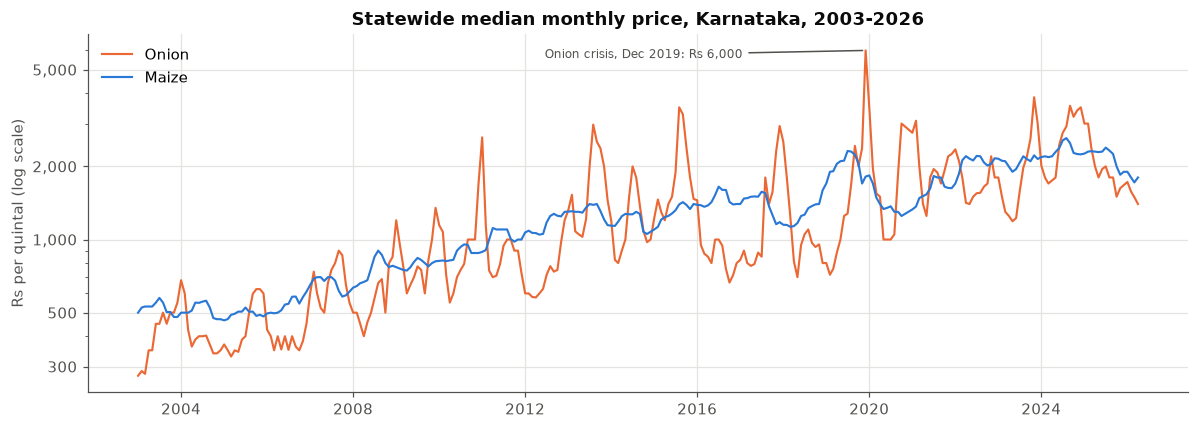

,crop,period,CV %,trend adj. R2,CDVI %,growth % per year (2004-2025)
0,Onion,2003-2015,67.6,0.5,47.9,NaN
1,Onion,2016-2025,49.6,0.2,43.2,NaN
2,Onion,2003-2025,67.2,0.5,48.3,7.7
3,Maize,2003-2015,35.6,0.9,11.3,NaN
4,Maize,2016-2025,22.2,0.6,14.3,NaN
5,Maize,2003-2025,46.2,0.9,15.0,7.5


In [6]:
state_month = (mm.groupby(["commodity", "ym"])["price"].median().unstack(0)[CROPS])
state_month.index = state_month.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 4))
for crop in CROPS:
    ax.plot(state_month.index, state_month[crop], color=CROP_COLOR[crop], linewidth=1.4, label=crop)
ax.set_yscale("log")
ax.set_yticks([300, 500, 1000, 2000, 5000]); ax.set_yticklabels(["300", "500", "1,000", "2,000", "5,000"])
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_ylabel("Rs per quintal (log scale)")
ax.set_title("Statewide median monthly price, Karnataka, 2003-2026")
peak = state_month["Onion"].idxmax()
ax.annotate(f"Onion crisis, {peak:%b %Y}: Rs {state_month['Onion'].max():,.0f}", (peak, state_month["Onion"].max()),
            textcoords="offset points", xytext=(-210, -5), fontsize=8, color=MUTED,
            arrowprops=dict(arrowstyle="-", color=MUTED))
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

def cdvi(series):
    s = series.dropna()
    t = np.arange(len(s))
    slope, intercept, r, p, se = stats.linregress(t, s.to_numpy())
    n, k = len(s), 1
    adj_r2 = 1 - (1 - r**2) * (n - 1) / (n - k - 1)
    cv = 100 * s.std() / s.mean()
    return cv, adj_r2, cv * np.sqrt(max(0, 1 - adj_r2))

rows = []
for crop in CROPS:
    yearly = state_month[crop].groupby(state_month.index.year).median()
    growth = (yearly.loc[2025] / yearly.loc[2004]) ** (1 / 21) - 1
    for label, a, b in [("2003-2015", "2003", "2015"), ("2016-2025", "2016", "2025"), ("2003-2025", "2003", "2025")]:
        cv, r2, ci = cdvi(state_month.loc[a:b, crop])
        rows.append({"crop": crop, "period": label, "CV %": cv, "trend adj. R2": r2, "CDVI %": ci,
                     "growth % per year (2004-2025)": 100 * growth if label == "2003-2025" else np.nan})
instability = pd.DataFrame(rows).round(1)
instability

**What this shows.** Both crops have become more expensive in rupees over time (partly general inflation), but in
very different ways: maize climbs smoothly, while onion jumps up and down around its trend. Onion's instability index
is several times maize's in both periods. For a farmer this means the **sell-or-store question matters far more for
onion**: the possible gain from good timing is larger, and so is the possible loss.

## 4. When are prices low and high, and is that timing reliable? (seasonality)

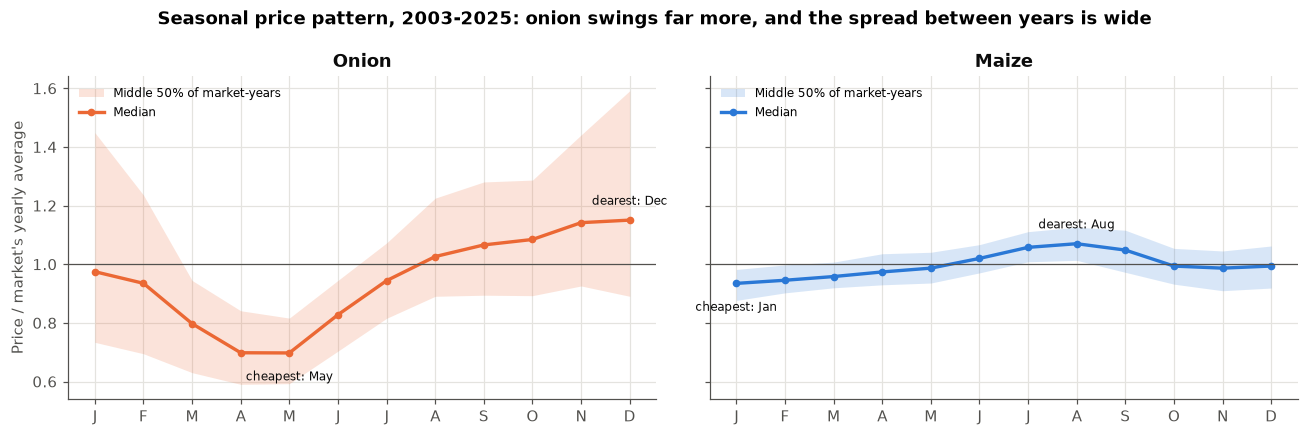

,Onion,Maize
cheapest month,May,Jan
dearest month,Dec,Aug
cheapest (x yearly avg),0.7,0.93
dearest (x yearly avg),1.15,1.07
dearest / cheapest,1.65,1.14


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
season_table = {}
for ax, crop in zip(axes, CROPS):
    s = mm[(mm["commodity"] == crop) & mm["full_year"]]
    q = s.groupby("month")["seasonal_rel"].quantile([0.25, 0.5, 0.75]).unstack()
    season_table[crop] = q[0.5]
    ax.fill_between(q.index, q[0.25], q[0.75], color=CROP_COLOR[crop], alpha=0.18, linewidth=0, label="Middle 50% of market-years")
    ax.plot(q.index, q[0.5], color=CROP_COLOR[crop], linewidth=2.2, marker="o", markersize=4, label="Median")
    ax.axhline(1, color=MUTED, linewidth=0.8)
    lo, hi = q[0.5].idxmin(), q[0.5].idxmax()
    ax.annotate(f"cheapest: {MONTHS[lo-1]}", (lo, q.loc[lo, 0.5]), textcoords="offset points", xytext=(0, -18), ha="center", fontsize=8, color=INK)
    ax.annotate(f"dearest: {MONTHS[hi-1]}", (hi, q.loc[hi, 0.5]), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8, color=INK)
    ax.set_xticks(range(1, 13)); ax.set_xticklabels([m[0] for m in MONTHS])
    ax.set_title(crop); ax.legend(frameon=False, fontsize=8, loc="upper left")
axes[0].set_ylabel("Price / market's yearly average")
fig.suptitle("Seasonal price pattern, 2003-2025: onion swings far more, and the spread between years is wide", fontweight="bold")
plt.tight_layout(); plt.show()

season_summary = pd.DataFrame({crop: {
    "cheapest month": MONTHS[season_table[crop].idxmin() - 1],
    "dearest month": MONTHS[season_table[crop].idxmax() - 1],
    "cheapest (x yearly avg)": round(season_table[crop].min(), 2),
    "dearest (x yearly avg)": round(season_table[crop].max(), 2),
    "dearest / cheapest": round(season_table[crop].max() / season_table[crop].min(), 2)} for crop in CROPS})
season_summary

The chart above is an average over all years. The heatmap below shows **each year separately**, with a dot on the
cheapest month of that year. If the season were perfectly regular, the dots would form a straight vertical line.

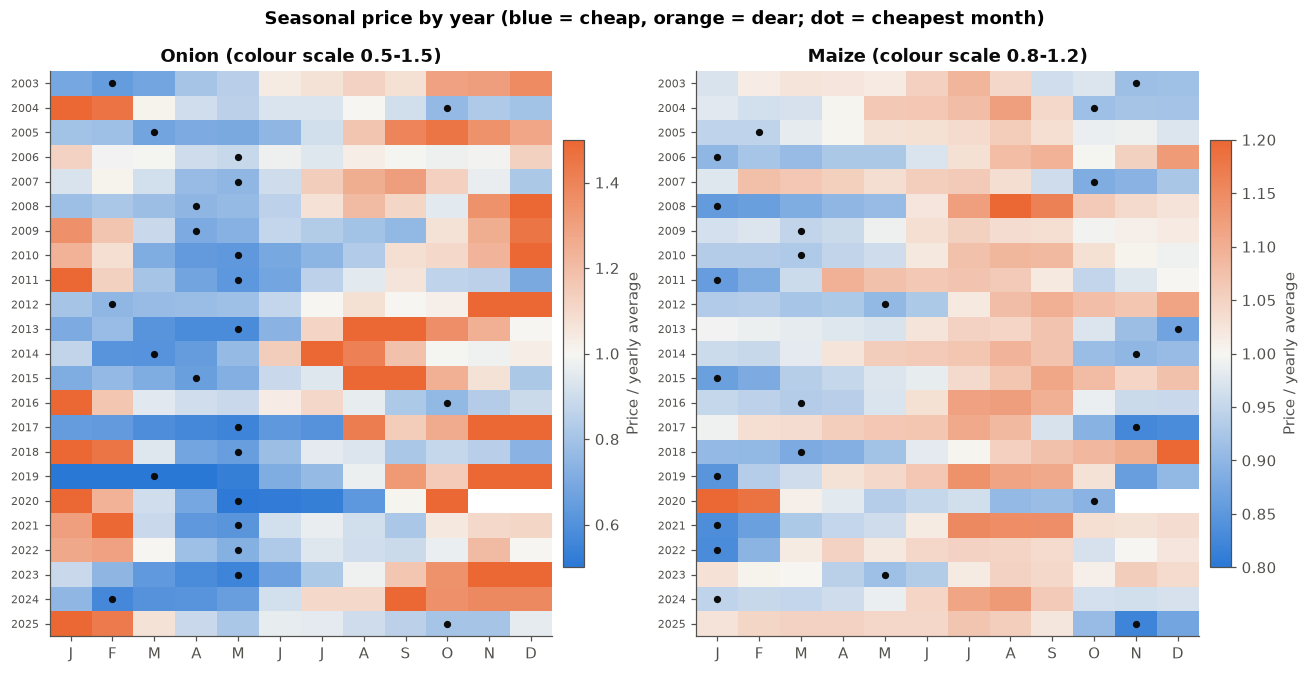

Share of market-years whose cheapest month is ... (%)


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
commodity,,,,,,,,,,,,
Onion,7.3,12.1,11.6,25.6,22.9,5.2,1.7,1.0,2.3,6.0,1.9,2.5
Maize,31.1,7.6,8.7,5.8,5.8,3.1,1.2,2.1,4.0,9.0,12.4,9.4


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6.2))
for ax, crop, (vmin, vmax) in zip(axes, CROPS, [(0.5, 1.5), (0.8, 1.2)]):
    s = mm[(mm["commodity"] == crop) & mm["full_year"] & (mm["year"] <= 2025)]
    grid = s.groupby(["year", "month"])["seasonal_rel"].median().unstack()
    im = ax.imshow(grid.values, aspect="auto", cmap=DIVERGING, vmin=vmin, vmax=vmax)
    lows = np.nanargmin(grid.values, axis=1)
    ax.scatter(lows, np.arange(len(grid)), s=14, color=INK, zorder=3)
    ax.set_xticks(range(12)); ax.set_xticklabels([m[0] for m in MONTHS])
    ax.set_yticks(range(len(grid))); ax.set_yticklabels(grid.index, fontsize=7)
    ax.set_title(f"{crop} (colour scale {vmin}-{vmax})"); ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="Price / yearly average")
fig.suptitle("Seasonal price by year (blue = cheap, orange = dear; dot = cheapest month)", fontweight="bold")
plt.tight_layout(); plt.show()

# In which month does each market-year hit its lowest price?
full = mm[mm["full_year"] & (mm["year"] <= 2025)]
low_rows = full.loc[full.groupby(["commodity", "market", "year"])["price"].idxmin()]
low_share = (low_rows.groupby("commodity")["month"].value_counts(normalize=True).unstack(0)
             .reindex(range(1, 13)).fillna(0)[CROPS] * 100).round(1)
low_share.index = MONTHS
print("Share of market-years whose cheapest month is ... (%)")
low_share.T

**What this shows.**
- **Onion** is cheapest around **April-May** (when the rabi crop arrives) and dearest around **October-December**.
  The typical dearest month is about 1.6 times the cheapest.
- **Maize** is cheapest in **January**, after the kharif harvest, and dearest in **July-August**, but its swing is small
  (the dearest month is only about 14% above the cheapest).
- **The timing is not fixed.** For onion, only about half of market-years have their low in April or May; the rest
  scatter across the year. In some years the pattern breaks completely: in 2004, 2016 and 2025 onion was cheapest in
  October, and in 2019 prices stayed low until April and then rose to a crisis peak in December.
  This matches what Patil et al. (2026) found for Kolar tomato. A farmer who always sells or stores by the calendar
  will sometimes be wrong, which is why the project builds a forecast (Notebook 5) and tests it (Notebook 6).

## 5. If I store after harvest, how much do I gain, and how often do I lose? (bivariate)

The key relationship for the project: **price gain against months stored**. For each market-year, the gain from
storing for *k* months is `price in (harvest month + k) / price in harvest month - 1`.

To avoid choosing the start month with the same data that is later tested, the **harvest month is chosen from
2003-2015 only** (the cheapest month in that period), and the gains are then measured on **2016-2025**.

The 95% confidence bands use a **cluster bootstrap by year** (Section 9 explains why): whole years are resampled,
because markets in the same year share the same shocks.

Harvest (start) month chosen from 2003-2015: {'Onion': 'Apr', 'Maize': 'Jan'}


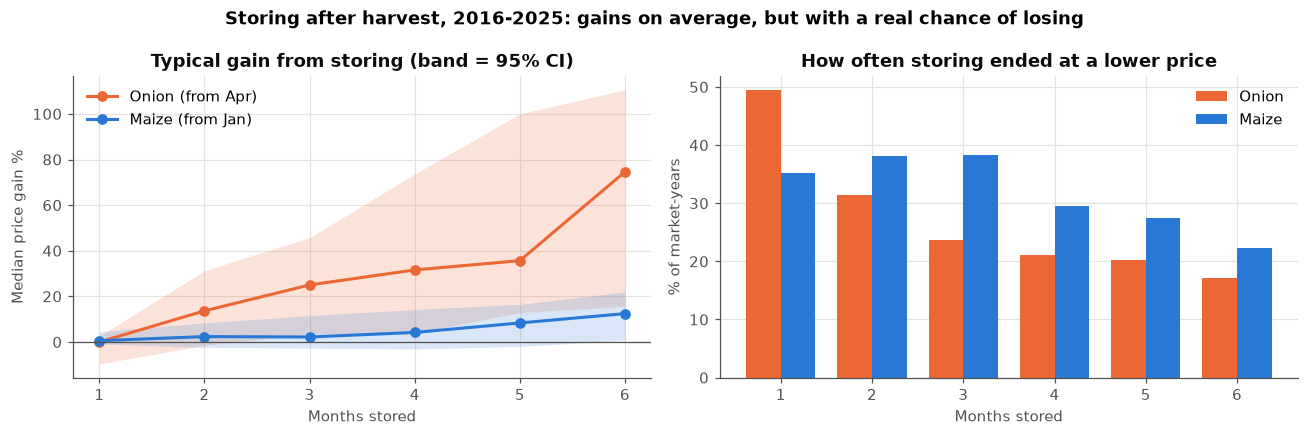

,crop,months stored,market-years,median gain %,CI low %,CI high %,share that lost money %
0,Onion,1,249,0.0,-9.6,2.6,49.4
1,Onion,2,245,13.6,-1.5,31.2,31.4
2,Onion,3,241,25.0,3.6,45.7,23.7
3,Onion,4,241,31.6,3.9,73.7,21.2
4,Onion,5,233,35.7,12.9,100.0,20.2
5,Onion,6,222,74.6,15.6,110.6,17.1
6,Maize,1,618,0.5,-0.9,4.5,35.1
7,Maize,2,579,2.4,-2.4,8.3,38.2
8,Maize,3,526,2.2,-2.7,11.5,38.2
9,Maize,4,505,4.2,-3.1,14.2,29.5


In [9]:
def cheapest_month(crop, first_year, last_year):
    s = mm[(mm["commodity"] == crop) & mm["full_year"] & mm["year"].between(first_year, last_year)]
    return int(s.groupby("month")["seasonal_rel"].median().idxmin())

HARVEST_MONTH = {crop: cheapest_month(crop, 2003, 2015) for crop in CROPS}
print("Harvest (start) month chosen from 2003-2015:", {c: MONTHS[m - 1] for c, m in HARVEST_MONTH.items()})

price_lookup = mm.set_index(["commodity", "market", "ym"])["price"]

def storage_gains(crop, k, first_year=2016, last_year=2025):
    # one row per market-year: price at the harvest month and k months later
    start = mm[(mm["commodity"] == crop) & (mm["month"] == HARVEST_MONTH[crop])
               & mm["year"].between(first_year, last_year)][["market", "district", "division", "year", "ym", "price"]]
    later_index = pd.MultiIndex.from_arrays([[crop] * len(start), start["market"], start["ym"] + k])
    start = start.assign(later=price_lookup.reindex(later_index).to_numpy()).dropna(subset=["later"])
    start["log_gain"] = np.log(start["later"] / start["price"])
    start["gain_pct"] = 100 * (start["later"] / start["price"] - 1)
    return start

def cluster_bootstrap_median(df, col="log_gain", reps=2000, seed=SEED):
    # resample whole years with replacement, then take the median over all market-years drawn
    rng = np.random.default_rng(seed)
    by_year = {y: g[col].to_numpy() for y, g in df.groupby("year")}
    years = np.array(list(by_year))
    meds = np.array([np.median(np.concatenate([by_year[y] for y in rng.choice(years, len(years))])) for _ in range(reps)])
    return np.percentile(meds, [2.5, 97.5])

curve = []
for crop in CROPS:
    for k in range(1, 7):
        g = storage_gains(crop, k)
        lo, hi = cluster_bootstrap_median(g)
        curve.append({"crop": crop, "months stored": k, "market-years": len(g),
                      "median gain %": 100 * np.expm1(g["log_gain"].median()),
                      "CI low %": 100 * np.expm1(lo), "CI high %": 100 * np.expm1(hi),
                      "share that lost money %": 100 * (g["log_gain"] < 0).mean()})
curve = pd.DataFrame(curve)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for crop in CROPS:
    c = curve[curve["crop"] == crop]
    axes[0].fill_between(c["months stored"], c["CI low %"], c["CI high %"], color=CROP_COLOR[crop], alpha=0.18, linewidth=0)
    axes[0].plot(c["months stored"], c["median gain %"], color=CROP_COLOR[crop], marker="o", linewidth=2,
                 label=f"{crop} (from {MONTHS[HARVEST_MONTH[crop] - 1]})")
axes[0].axhline(0, color=MUTED, linewidth=0.8)
axes[0].set_xlabel("Months stored"); axes[0].set_ylabel("Median price gain %")
axes[0].set_title("Typical gain from storing (band = 95% CI)"); axes[0].legend(frameon=False)

width = 0.38
for i, crop in enumerate(CROPS):
    c = curve[curve["crop"] == crop]
    axes[1].bar(c["months stored"] + (i - 0.5) * width, c["share that lost money %"], width=width,
                color=CROP_COLOR[crop], label=crop)
axes[1].set_xlabel("Months stored"); axes[1].set_ylabel("% of market-years")
axes[1].set_title("How often storing ended at a lower price"); axes[1].legend(frameon=False)
fig.suptitle("Storing after harvest, 2016-2025: gains on average, but with a real chance of losing", fontweight="bold")
plt.tight_layout(); plt.show()
curve.round(1)

**What this shows.**
- **Onion:** storing from the April low raises the price by a median of about 25% after 3 months and more after
  5-6 months. But in roughly **1 market-year in 4 or 5 the price was lower** when the farmer sold, before even counting
  storage losses.
- **Maize:** the gain is only a few percent for 1-4 months, and in about a third of market-years storing lost money.
  A few percent is about what the money tied up in stored grain would cost in interest, so storing maize for a short
  time rarely pays.
- These are **gross price gains**. Onions lose weight and some rot in storage, so the real gain is smaller; Hypothesis
  H2 (Section 10) tests the gain and shows how the answer changes with storage losses.

## 6. How risky is each crop? (subgroup comparison)

Two measures of risk:
- **Within-year swing** of a market: (highest month − lowest month) / average month, for each market-year.
  This is the room a farmer has to gain or lose by choosing *when* to sell.
- **Weekly price change**: the log change in a market's price from one week to the next, using only weeks where both
  prices were actually reported (no filled values).

,Onion,Maize
market-years,481.0,1043.0
median within-year swing %,110.3,29.1
market-years with swing > 50 %,93.1,6.9
SD of weekly change %,17.2,7.1
weeks with a change > 20 % (%),21.6,3.0


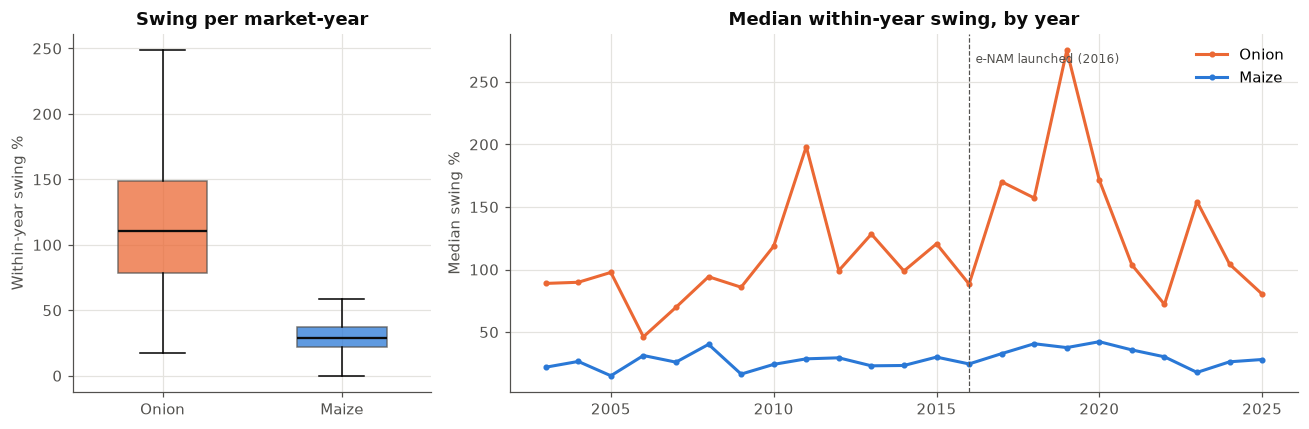

In [10]:
swing = (mm[mm["full_year"] & (mm["year"] <= 2025)]
         .groupby(["commodity", "division", "district", "market", "year"])["price"]
         .agg(lambda s: (s.max() - s.min()) / s.mean()).rename("swing").reset_index())

obs = panel.dropna(subset=["price"]).sort_values(["commodity", "market", "week"]).copy()
obs["gap"] = obs.groupby(["commodity", "market"])["week"].diff().dt.days
obs["weekly_change"] = np.log(obs["price"]).groupby([obs["commodity"], obs["market"]]).diff()
weekly = obs[obs["gap"] == 7]

risk = pd.DataFrame({crop: {
    "market-years": int((swing["commodity"] == crop).sum()),
    "median within-year swing %": 100 * swing.loc[swing["commodity"] == crop, "swing"].median(),
    "market-years with swing > 50 %": 100 * (swing.loc[swing["commodity"] == crop, "swing"] > 0.5).mean(),
    "SD of weekly change %": 100 * weekly.loc[weekly["commodity"] == crop, "weekly_change"].std(),
    "weeks with a change > 20 % (%)": 100 * (weekly.loc[weekly["commodity"] == crop, "weekly_change"].abs() > np.log(1.2)).mean(),
} for crop in CROPS}).round(1)
display(risk)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2.2]})
ax = axes[0]
parts = ax.boxplot([100 * swing.loc[swing["commodity"] == c, "swing"] for c in CROPS], tick_labels=CROPS, widths=0.5,
                   patch_artist=True, showfliers=False, medianprops=dict(color=INK, linewidth=1.5))
for patch, c in zip(parts["boxes"], CROPS):
    patch.set_facecolor(CROP_COLOR[c]); patch.set_alpha(0.75); patch.set_edgecolor(MUTED)
ax.set_ylabel("Within-year swing %"); ax.set_title("Swing per market-year")

ax = axes[1]
yearly_swing = swing.groupby(["commodity", "year"])["swing"].median().unstack(0)
for c in CROPS:
    ax.plot(yearly_swing.index, 100 * yearly_swing[c], color=CROP_COLOR[c], linewidth=2, marker="o", markersize=3, label=c)
ax.axvline(2016, color=MUTED, linewidth=0.8, linestyle="--")
ax.text(2016.2, ax.get_ylim()[1] * 0.92, "e-NAM launched (2016)", fontsize=8, color=MUTED)
ax.set_ylabel("Median swing %"); ax.set_title("Median within-year swing, by year"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

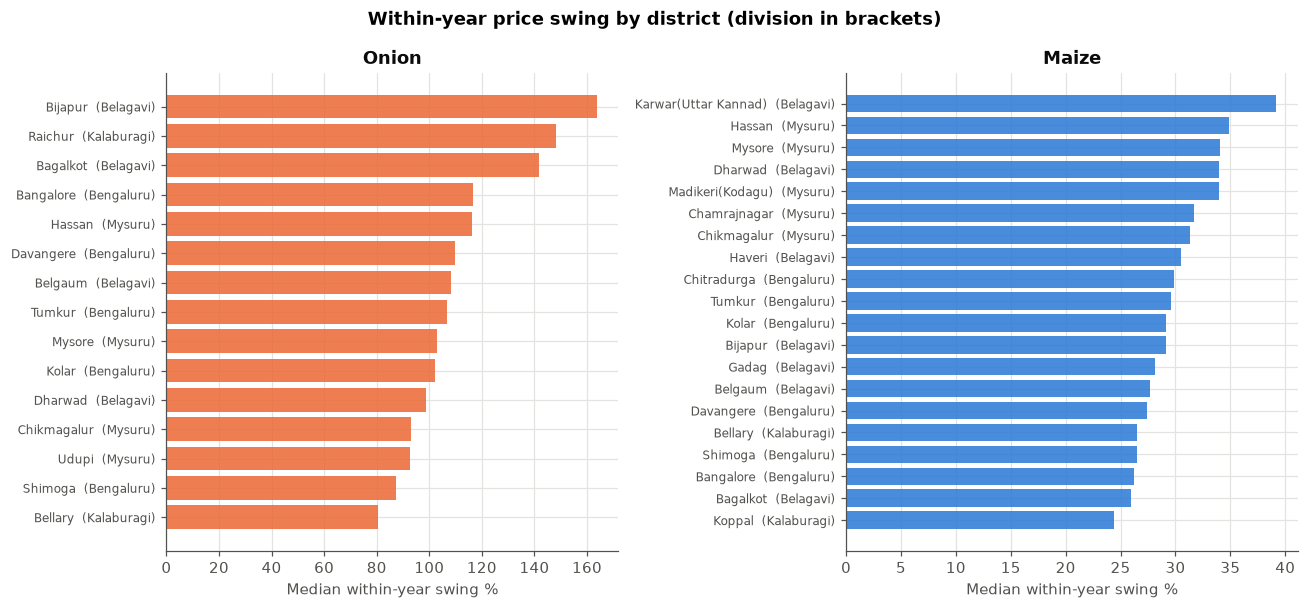

In [11]:
# Does risk differ by district? Onion and maize, districts with at least 15 market-years
dist_swing = (swing.groupby(["commodity", "division", "district"])["swing"]
                   .agg(["median", "size"]).reset_index().query("size >= 15"))
fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
for ax, crop in zip(axes, CROPS):
    d = dist_swing[dist_swing["commodity"] == crop].sort_values("median")
    ax.barh(d["district"] + "  (" + d["division"] + ")", 100 * d["median"], color=CROP_COLOR[crop], alpha=0.85)
    ax.set_xlabel("Median within-year swing %"); ax.set_title(crop); ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Within-year price swing by district (division in brackets)", fontweight="bold")
plt.tight_layout(); plt.show()

**What this shows.** In a typical year an onion market's price moves by around 100% of its average between its
cheapest and dearest month; for maize the figure is around 30%. Weekly jumps of more than 20% are common for onion
and rare for maize. Risk also varies by district, which is why later notebooks keep the market and district as
features rather than treating Karnataka as one market. There is no obvious drop in onion swing after e-NAM (2016):
better connected markets have not removed the seasonal swing.

## 7. Where should I sell? (geographical)

The **premium** compares a market with the statewide median in the same month, so it is not affected by season or
inflation. Each market-year gets its average premium, and districts are compared on those values.

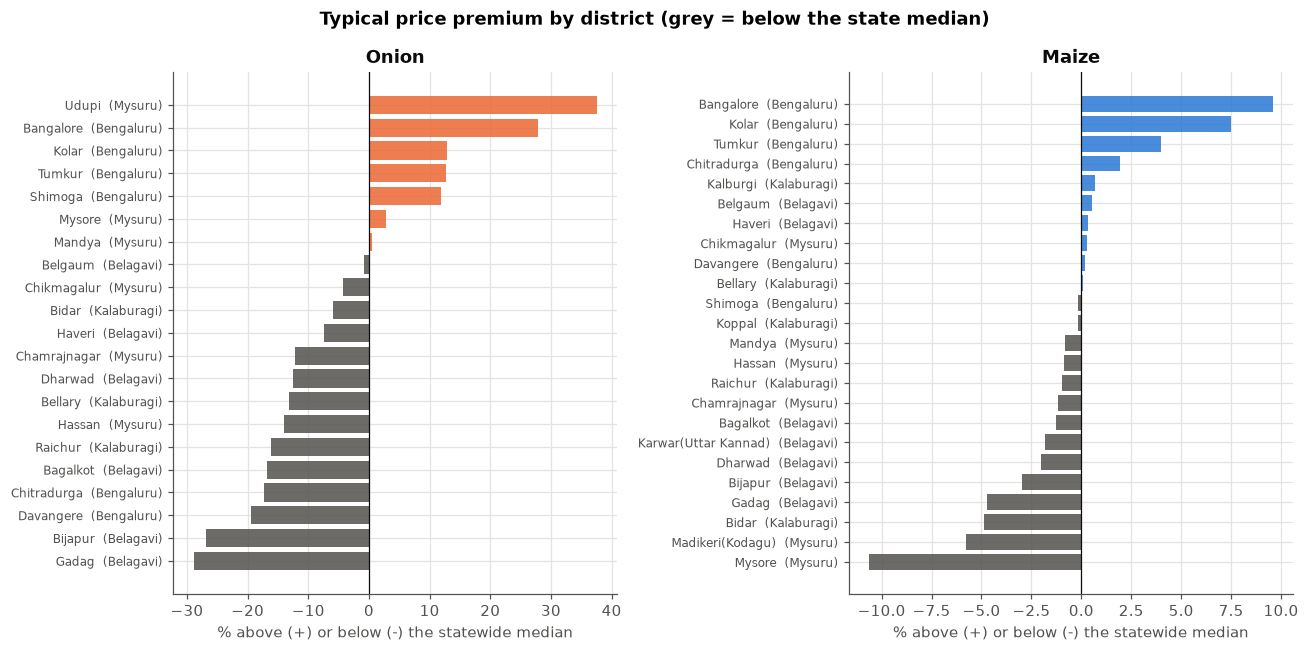

In [12]:
mm["log_premium"] = np.log(mm["premium"])
market_year_prem = (mm[mm["year"] <= 2025].groupby(["commodity", "division", "district", "market", "year"])["log_premium"]
                      .mean().reset_index())
dist_prem = (market_year_prem.groupby(["commodity", "division", "district"])["log_premium"]
                              .agg(["median", "size"]).reset_index().query("size >= 15"))
dist_prem["premium %"] = 100 * np.expm1(dist_prem["median"])

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, crop in zip(axes, CROPS):
    d = dist_prem[dist_prem["commodity"] == crop].sort_values("premium %")
    colors = [CROP_COLOR[crop] if v >= 0 else MUTED for v in d["premium %"]]
    ax.barh(d["district"] + "  (" + d["division"] + ")", d["premium %"], color=colors, alpha=0.85)
    ax.axvline(0, color=INK, linewidth=0.8)
    ax.set_xlabel("% above (+) or below (-) the statewide median"); ax.set_title(crop); ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Typical price premium by district (grey = below the state median)", fontweight="bold")
plt.tight_layout(); plt.show()

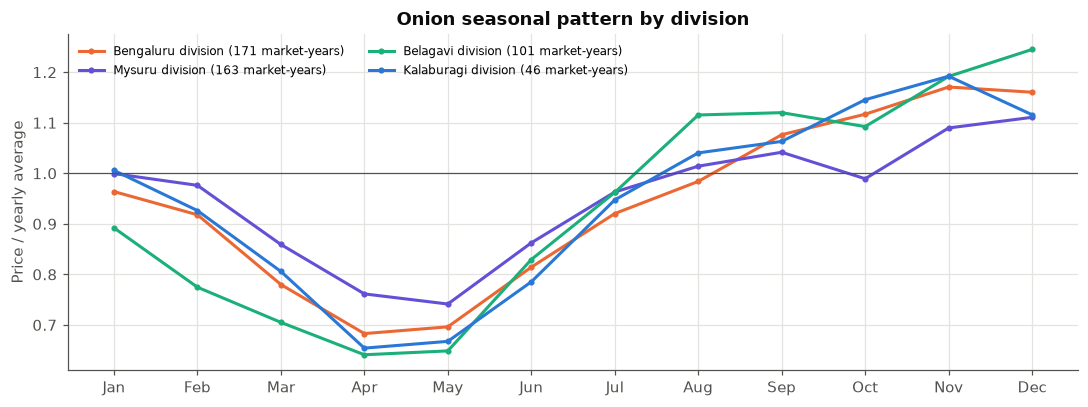

In [13]:
# Does the seasonal timing differ by region? Onion seasonal pattern for each division
fig, ax = plt.subplots(figsize=(10, 3.8))
div_colors = dict(zip(DIV_ORDER, [ORANGE, VIOLET, AQUA, BLUE]))
s = mm[(mm["commodity"] == "Onion") & mm["full_year"]]
for div in DIV_ORDER:
    q = s[s["division"] == div].groupby("month")["seasonal_rel"].median()
    n = s[s["division"] == div].groupby(["market", "year"]).ngroups
    ax.plot(q.index, q.values, color=div_colors[div], linewidth=2, marker="o", markersize=3, label=f"{div} division ({n} market-years)")
ax.axhline(1, color=MUTED, linewidth=0.8)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(MONTHS)
ax.set_ylabel("Price / yearly average"); ax.set_title("Onion seasonal pattern by division")
ax.legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

**What this shows.** For onion, the main growing districts of north and central Karnataka (for example Gadag,
Bijapur, Chitradurga, Davangere) sell well below the state median, while consumer centres such as Bangalore and Udupi
pay well above it. Part of this gap is transport and quality, so it is not free profit, but it shows **where** a
farmer sells matters as well as **when**. For maize the district differences are only a few percent. All four divisions
share the same broad onion season, with the low in spring, but the size and exact timing differ by region.

## 8. Do mandis move together? (multivariate)

If every mandi's price rises and falls together, a few statewide signals explain most of the price movement, which is
what PCA (Notebook 4) will measure. Here the **correlation of 4-week price changes** between the core markets from the
weekly panel is examined. Changes are used rather than price levels, because levels all share an upward trend that
would make every pair look correlated.

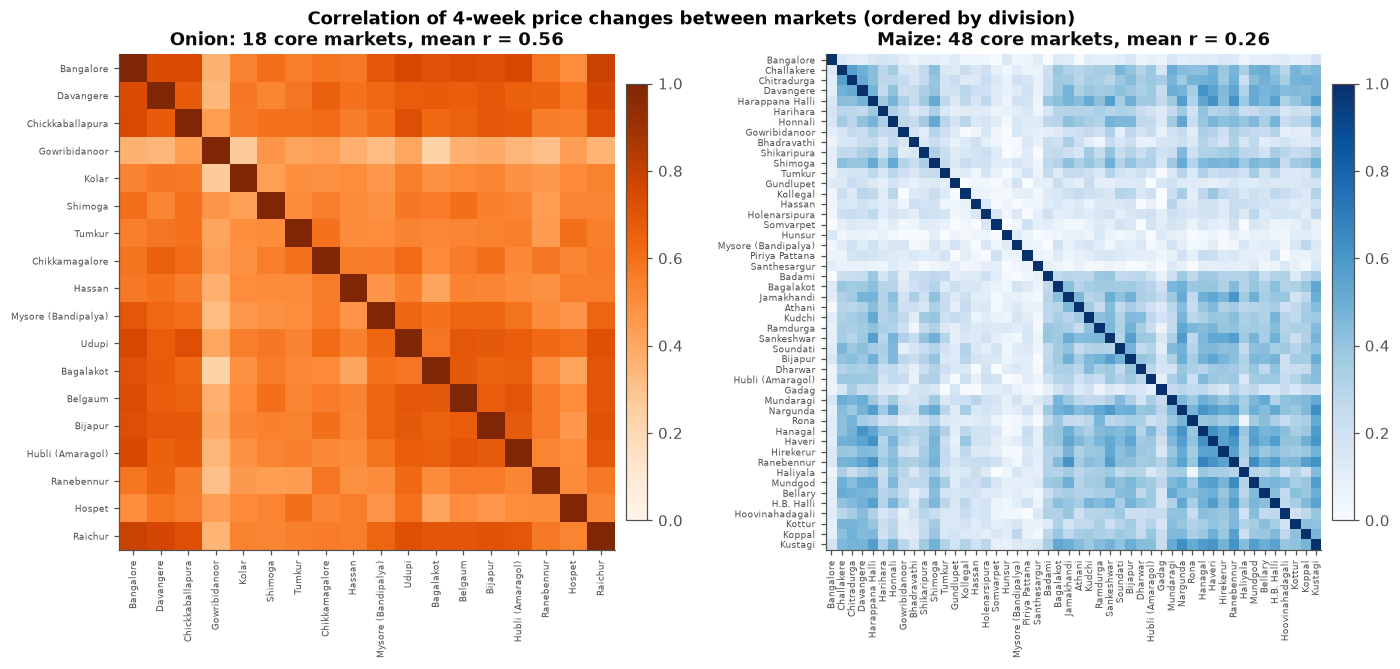

Mean correlation between pairs of markets: {'Onion': np.float64(0.56), 'Maize': np.float64(0.26)}
Correlation between the onion and maize statewide monthly changes: 0.14


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
mean_corr = {}
for ax, crop in zip(axes, CROPS):
    p = panel[panel["commodity"] == crop].pivot_table(index="week", columns="market", values="price_filled")
    order = (panel[panel["commodity"] == crop][["market", "district"]].drop_duplicates()
             .assign(division=lambda x: x["district"].map(DIVISION))
             .assign(div_rank=lambda x: x["division"].map({d: i for i, d in enumerate(DIV_ORDER)}))
             .sort_values(["div_rank", "district", "market"])["market"])
    change = np.log(p[order]).diff(4)
    corr = change.corr(min_periods=100)
    upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    mean_corr[crop] = upper.stack().mean()
    im = ax.imshow(corr.values, cmap="Blues" if crop == "Maize" else "Oranges", vmin=0, vmax=1)
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=90, fontsize=6)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=6)
    ax.set_title(f"{crop}: {len(order)} core markets, mean r = {mean_corr[crop]:.2f}"); ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
fig.suptitle("Correlation of 4-week price changes between markets (ordered by division)", fontweight="bold")
plt.tight_layout(); plt.show()

both = state_month[CROPS].apply(np.log).diff()
print("Mean correlation between pairs of markets:", {k: round(v, 2) for k, v in mean_corr.items()})
print("Correlation between the onion and maize statewide monthly changes:", round(both.corr().iloc[0, 1], 2))

**What this shows.** Onion markets move together strongly: when onion prices rise in one mandi, they rise in most
others within the same month. Maize markets are also positively correlated but less tightly, because maize price
changes are small and local noise matters more. Onion and maize prices are almost unrelated to each other, so they
need separate models. The strong co-movement means a few common factors should capture most of the movement across
mandis; Notebook 4 tests this with PCA.

## 9. Sampling: if we can only watch 10 mandis, how should we pick them?

A price-monitoring agency, or the project's dashboard, cannot follow every mandi in detail. Suppose we can follow
**10 markets** and want to estimate the **average onion (or maize) price across all Karnataka markets for 2016-2025**.
Because the full data is available, the true value is known, so each sampling method can be checked by repeating it
2,000 times and measuring how far its estimates fall from the truth.

| Method | How the 10 markets are chosen | Why it might help |
| --- | --- | --- |
| Simple random sampling (SRS) | any 10 markets, equally likely | unbiased; the baseline |
| Stratified sampling | markets split into the 4 revenue divisions; each division gets a share of the 10 in proportion to its size | divisions have different price levels (Section 7), so every region is always represented |
| Systematic sampling | markets listed by division and district; a random start, then every *k*-th market | spreads the sample across the map like stratification, with only one random number |
| Bootstrap (used later) | resample the data with replacement | gives confidence intervals without assuming a normal distribution |

**Population:** markets with at least 24 months of data in 2016-2025. **Value estimated:** the mean of each market's
average monthly price.

,crop,markets in population,n,method,true value,bias,standard error,RMSE,within 5% of truth (%)
6,Onion,38,10,Simple random,1780.9,-2.6,108.4,108.5,59.2
7,Onion,38,10,Stratified by division,1780.9,-0.1,84.7,84.7,69.5
8,Onion,38,10,Systematic,1780.9,0.5,97.0,97.0,64.4
21,Maize,96,10,Simple random,1705.1,-0.4,57.2,57.2,86.6
22,Maize,96,10,Stratified by division,1705.1,-1.7,50.1,50.1,91.4
23,Maize,96,10,Systematic,1705.1,1.6,38.0,38.1,97.7


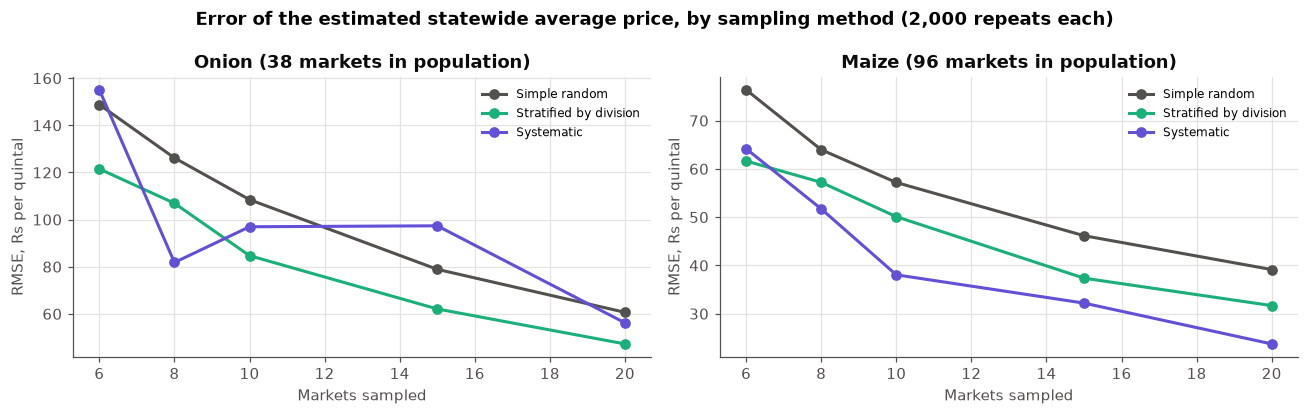

In [15]:
pop = (mm[mm["year"].between(2016, 2025)]
       .groupby(["commodity", "division", "district", "market"])["price"].agg(["mean", "size"]).reset_index()
       .query("size >= 24"))
pop["div_rank"] = pop["division"].map({d: i for i, d in enumerate(DIV_ORDER)})
pop = pop.sort_values(["commodity", "div_rank", "district", "market"]).reset_index(drop=True)

def allocate(sizes, n):
    # proportional allocation, at least one market per division, total exactly n
    share = sizes / sizes.sum()
    alloc = np.maximum(1, np.floor(share * n)).astype(int)
    order = (share * n - np.floor(share * n)).sort_values(ascending=False).index
    i = 0
    while alloc.sum() < n:
        alloc[order[i % len(order)]] += 1; i += 1
    while alloc.sum() > n:
        alloc[alloc.idxmax()] -= 1
    return alloc

def srs(frame, n, rng):
    return frame["mean"].to_numpy()[rng.choice(len(frame), n, replace=False)].mean()

def stratified(frame, n, rng):
    sizes = frame["division"].value_counts()
    alloc = allocate(sizes, n)
    estimate = 0.0
    for div, a in alloc.items():
        values = frame.loc[frame["division"] == div, "mean"].to_numpy()
        estimate += (sizes[div] / sizes.sum()) * values[rng.choice(len(values), min(a, len(values)), replace=False)].mean()
    return estimate

def systematic(frame, n, rng):
    k = len(frame) / n
    idx = (rng.uniform(0, k) + k * np.arange(n)).astype(int)
    return frame["mean"].to_numpy()[idx].mean()

METHODS = {"Simple random": srs, "Stratified by division": stratified, "Systematic": systematic}
REPS = 2000
rng = np.random.default_rng(SEED)
rows = []
for crop in CROPS:
    frame = pop[pop["commodity"] == crop].reset_index(drop=True)
    truth = frame["mean"].mean()
    for n in [6, 8, 10, 15, 20]:
        for name, f in METHODS.items():
            est = np.array([f(frame, n, rng) for _ in range(REPS)])
            rows.append({"crop": crop, "markets in population": len(frame), "n": n, "method": name,
                         "true value": truth, "bias": est.mean() - truth, "standard error": est.std(),
                         "RMSE": np.sqrt(((est - truth) ** 2).mean()),
                         "within 5% of truth (%)": 100 * (np.abs(est / truth - 1) < 0.05).mean()})
sampling = pd.DataFrame(rows)
display(sampling[sampling["n"] == 10].round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
method_colors = {"Simple random": MUTED, "Stratified by division": AQUA, "Systematic": VIOLET}
for ax, crop in zip(axes, CROPS):
    s = sampling[sampling["crop"] == crop]
    for name in METHODS:
        m = s[s["method"] == name]
        ax.plot(m["n"], m["RMSE"], color=method_colors[name], marker="o", linewidth=2, label=name)
    ax.set_xlabel("Markets sampled"); ax.set_ylabel("RMSE, Rs per quintal")
    ax.set_title(f"{crop} ({s['markets in population'].iloc[0]} markets in population)")
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("Error of the estimated statewide average price, by sampling method (2,000 repeats each)", fontweight="bold")
plt.tight_layout(); plt.show()

**Bootstrap, and why the unit of resampling matters.** The confidence intervals in Section 5 and in H2 come from
the bootstrap. A naive bootstrap resamples individual market-years. But markets in the same year share the same
weather and the same national supply shocks (2019 was a bad year everywhere), so they are not independent. The
**cluster bootstrap** resamples whole years instead. The comparison below shows the difference for the 3-month onion
and maize storage gain.

In [16]:
rows = []
for crop in CROPS:
    g = storage_gains(crop, 3)
    rng = np.random.default_rng(SEED)
    naive = np.array([np.median(rng.choice(g["log_gain"].to_numpy(), len(g))) for _ in range(REPS)])
    lo_n, hi_n = np.percentile(naive, [2.5, 97.5])
    lo_c, hi_c = cluster_bootstrap_median(g)
    for name, lo, hi in [("naive (market-years)", lo_n, hi_n), ("cluster (whole years)", lo_c, hi_c)]:
        rows.append({"crop": crop, "bootstrap": name, "median gain %": 100 * np.expm1(g["log_gain"].median()),
                     "95% CI low %": 100 * np.expm1(lo), "95% CI high %": 100 * np.expm1(hi),
                     "CI width (points)": 100 * (np.expm1(hi) - np.expm1(lo))})
pd.DataFrame(rows).round(1)

,crop,bootstrap,median gain %,95% CI low %,95% CI high %,CI width (points)
0,Onion,naive (market-years),25.0,18.2,33.9,15.7
1,Onion,cluster (whole years),25.0,3.6,45.7,42.2
2,Maize,naive (market-years),2.2,0.9,3.5,2.7
3,Maize,cluster (whole years),2.2,-2.7,11.5,14.2


**What sampling shows.**
- All three methods are close to unbiased; they differ in **precision**.
- For **onion**, stratified sampling is the most accurate at every sample size, because price levels differ strongly
  between regions (Section 7); making sure every division is represented removes that source of error.
  Systematic sampling is **erratic** for onion: with only 38 markets and an interval of about 4, there are only a
  handful of different samples it can draw, so its accuracy depends on how the list happens to line up with the interval.
- For **maize** (96 markets), systematic sampling is the most accurate and stratified is second; both beat simple random
  sampling. Ordering the list by division and district spreads the sample across districts as well as divisions.
- **Practical recommendation:** when choosing a small set of mandis to monitor (for example in the dashboard), pick them
  across all four divisions rather than at random.
- The cluster bootstrap gives **wider** confidence intervals than the naive bootstrap. The naive one is too confident,
  because it treats correlated markets as independent. The project reports the cluster version.

## 10. Hypothesis tests

Five hypotheses, each tied to the sell-or-store decision. Every test is run separately for onion and maize.

**Choices that apply to all tests**
- Significance level α = 0.05.
- **Non-parametric tests**, because Section 2 showed prices are skewed and heavy-tailed.
- **Unit of analysis** is the market-month or market-year, not the individual record, to reduce dependence between
  records from the same market and week.
- **Multiple comparisons:** 9 primary p-values are tested (H1, H2, H4 and H5 for each crop, and H3 comparing the two
  crops in one test), so they are corrected with the
  **Holm method**, which controls the chance of any false positive across the whole family.
- **Effect sizes** are reported with every test: with thousands of observations even tiny differences give small
  p-values, so the effect size tells whether a difference is large enough to matter to a farmer.

| # | Question | Test | Effect size |
| --- | --- | --- | --- |
| H1 | Do prices differ by calendar month (is there seasonality)? | Kruskal-Wallis | epsilon² |
| H2 | Does storing for 3 months after harvest raise the price? | Wilcoxon signed-rank, one-sided | median gain + rank-biserial r |
| H3 | Is onion riskier than maize? | Mann-Whitney U, one-sided (+ Brown-Forsythe) | rank-biserial r |
| H4 | Does the price depend on the district where it is sold? | Kruskal-Wallis | epsilon² |
| H5 | Has the timing of the yearly low changed between 2003-2015 and 2016-2025? | Chi-square test of homogeneity (+ goodness of fit) | Cramér's V |

In [17]:
results = []   # one row per primary test

def add_result(h, crop, test, statistic, p, effect_name, effect, n, note=""):
    results.append({"hypothesis": h, "crop": crop, "test": test, "statistic": statistic, "p_value": p,
                    "effect size": effect_name, "effect": effect, "n": n, "note": note})

def epsilon_squared(H, n, k):
    return (H - k + 1) / (n - k)

### H1: Do prices differ by calendar month?

- **H0:** the seasonal relative price has the same distribution in every calendar month.
- **H1:** at least one month differs.
- **Data:** seasonal relative price of every market-month in a market-year with at least 10 months (2003-2025).
- **Test:** Kruskal-Wallis (non-parametric one-way ANOVA on ranks). Assumes independent observations and groups of
  similar shape; months from the same market-year are related, so the effect size matters more than the p-value.

In [18]:
for crop in CROPS:
    s = mm[(mm["commodity"] == crop) & mm["full_year"] & (mm["year"] <= 2025)]
    groups = [g["seasonal_rel"].to_numpy() for _, g in s.groupby("month")]
    H, p = stats.kruskal(*groups)
    eps = epsilon_squared(H, len(s), 12)
    add_result("H1 seasonality", crop, "Kruskal-Wallis", H, p, "epsilon squared", eps, len(s))
    p_text = "< 1e-300" if p == 0 else f"{p:.2e}"
    print(f"{crop}: H = {H:,.1f}, p {'' if p == 0 else '= '}{p_text}, epsilon squared = {eps:.3f}  (n = {len(s):,} market-months)")

Onion: H = 1,508.5, p < 1e-300, epsilon squared = 0.271  (n = 5,542 market-months)
Maize: H = 2,092.7, p < 1e-300, epsilon squared = 0.175  (n = 11,879 market-months)


**Interpretation.** Seasonality is real for both crops. Epsilon squared is the share of variation in ranks
explained by the month: about 0.27 for onion and 0.18 for maize (values above 0.14 are usually called large).
So the month a farmer sells in matters for both crops, and much more in rupee terms for onion, whose swings are larger.

### H2: Does storing for 3 months after harvest raise the price?

- **H0:** the median log price change from the harvest month to 3 months later is 0 or less.
- **H1:** it is greater than 0 (storing raises the price).
- **Data:** market-years in **2016-2025**. The harvest month (onion: April, maize: January) was chosen from
  **2003-2015** in Section 5, so the start month was not picked using the test data. The 3-month horizon is fixed in
  advance as a common storage period.
- **Test:** Wilcoxon signed-rank, one-sided, on the paired prices (same market, same year). Assumes the differences
  are roughly symmetric around their median. **Robustness check:** because markets in the same year are correlated,
  the test is repeated on one value per year (the median gain across markets), which gives about 10 independent values.

In [19]:
h2_rows = []
for crop in CROPS:
    g = storage_gains(crop, 3)
    w = stats.wilcoxon(g["log_gain"], alternative="greater")
    n = (g["log_gain"] != 0).sum()
    r_rb = 2 * w.statistic / (n * (n + 1) / 2) - 1          # matched-pairs rank-biserial correlation
    lo, hi = cluster_bootstrap_median(g)
    add_result("H2 storage gain (3 months)", crop, "Wilcoxon signed-rank (one-sided)", w.statistic, w.pvalue,
               "rank-biserial r", r_rb, len(g),
               f"median gain {100 * np.expm1(g['log_gain'].median()):.1f}% (95% CI {100 * np.expm1(lo):.1f} to {100 * np.expm1(hi):.1f})")
    by_year = g.groupby("year")["log_gain"].median()
    w_year = stats.wilcoxon(by_year, alternative="greater")
    h2_rows.append({"crop": crop, "start month": MONTHS[HARVEST_MONTH[crop] - 1], "market-years": len(g),
                    "median gain %": 100 * np.expm1(g["log_gain"].median()),
                    "95% CI (cluster bootstrap)": f"{100 * np.expm1(lo):.1f} to {100 * np.expm1(hi):.1f}",
                    "share that lost money %": 100 * (g["log_gain"] < 0).mean(),
                    "p (market-years)": w.pvalue, "rank-biserial r": r_rb,
                    "years with a gain": f"{(by_year > 0).sum()} of {len(by_year)}", "p (one value per year)": w_year.pvalue})
pd.DataFrame(h2_rows).round(3)

,crop,start month,market-years,median gain %,95% CI (cluster bootstrap),share that lost money %,p (market-years),rank-biserial r,years with a gain,p (one value per year)
0,Onion,Apr,241,25.000,3.6 to 45.7,23.651,0.0,0.609,9 of 10,0.010
1,Maize,Jan,526,2.178,-2.7 to 11.5,38.213,0.0,0.232,6 of 10,0.213


**Statistical significance is not the same as making money.** Stored onions lose weight and some rot, and stored
grain ties up money that could earn interest. Those costs are not in the price data, so the table below treats the
**total cost of storing for 3 months** (losses plus storage plus interest, as a % of the crop's value) as an assumption
and shows how often storing would still have paid. Notebook 6 turns these assumptions into adjustable sliders.

In [20]:
cost_levels = [0, 5, 10, 15, 20, 30]
rows = []
for crop in CROPS:
    g = storage_gains(crop, 3)
    net_ratio = g["later"] / g["price"]
    row = {"crop": crop}
    for cost in cost_levels:
        row[f"cost {cost}%"] = 100 * ((net_ratio * (1 - cost / 100)) > 1).mean()
    row["break-even cost % (median market-year)"] = 100 * (1 - 1 / net_ratio.median())
    rows.append(row)
print("% of market-years (2016-2025) in which storing for 3 months beat selling at harvest, after costs:")
pd.DataFrame(rows).set_index("crop").round(1)

% of market-years (2016-2025) in which storing for 3 months beat selling at harvest, after costs:


,cost 0%,cost 5%,cost 10%,cost 15%,cost 20%,cost 30%,break-even cost % (median market-year)
crop,,,,,,,
Onion,71.0,68.5,62.2,56.4,48.5,34.0,20.0
Maize,56.5,39.9,27.2,18.1,9.9,1.3,2.1


**Interpretation.**
- **Onion:** H0 is rejected. Storing from April to July raised the price in about three quarters of market-years, with
  a median gain of about 25%, and the gain holds when each year counts once. In practice, a typical market-year still
  comes out ahead if storage losses and costs over 3 months stay below roughly 20%, but the chance of ending up worse
  off rises quickly as costs grow. Storing onion pays **on average**, but it is a risky bet in any one year.
- **Maize:** the market-year test rejects H0, but the result does **not** survive the robustness check: only 6 of 10
  years showed a gain (p = 0.21 with one value per year), and the cluster-bootstrap interval includes 0. The small
  p-value came from treating 526 correlated market-years as independent. Even taken at face value, the median gain is
  only about 2%, and a cost of 5% over 3 months (interest at 7-12% a year is already 2-3%) makes storing worse than
  selling in about 60% of market-years. So for maize: **no reliable gain, and practically small even if real**.
- This is the core motivation for the forecast: a farmer needs to know **in which years** storing will pay, not just
  that it pays on average.

### H3: Is onion riskier than maize?

- **H0:** onion's within-year swing is not larger than maize's.
- **H1:** onion's within-year swing is larger (one-sided).
- **Data:** within-year swing of each market-year (2003-2025, at least 10 months).
- **Test:** Mann-Whitney U, one-sided. Assumes the two groups are independent, which holds because they are different
  crops. **Supporting test:** Brown-Forsythe test (Levene's test using medians) on weekly price changes, checking whether
  the spread of weekly changes differs.

In [21]:
o = swing.loc[swing["commodity"] == "Onion", "swing"]
m = swing.loc[swing["commodity"] == "Maize", "swing"]
u = stats.mannwhitneyu(o, m, alternative="greater")
r_rb = 2 * u.statistic / (len(o) * len(m)) - 1
add_result("H3 onion riskier than maize", "Onion vs Maize", "Mann-Whitney U (one-sided)", u.statistic, u.pvalue,
           "rank-biserial r", r_rb, len(o) + len(m),
           f"median swing onion {100 * o.median():.0f}% vs maize {100 * m.median():.0f}%")
bf = stats.levene(weekly.loc[weekly["commodity"] == "Onion", "weekly_change"],
                  weekly.loc[weekly["commodity"] == "Maize", "weekly_change"], center="median")
print(f"Mann-Whitney U = {u.statistic:,.0f}, p = {u.pvalue:.2e}, rank-biserial r = {r_rb:.2f}")
print(f"Median swing: onion {100 * o.median():.0f}%, maize {100 * m.median():.0f}% (onion is {o.median() / m.median():.1f} times larger)")
print(f"Brown-Forsythe on weekly changes: W = {bf.statistic:,.1f}, p = {bf.pvalue:.2e}")
# P(a random onion market-year swings more than a random maize market-year)
print(f"Probability a random onion market-year swings more than a random maize one: {(r_rb + 1) / 2:.2f}")

Mann-Whitney U = 486,090, p = 4.39e-191, rank-biserial r = 0.94
Median swing: onion 110%, maize 29% (onion is 3.8 times larger)
Brown-Forsythe on weekly changes: W = 5,927.3, p = 0.00e+00
Probability a random onion market-year swings more than a random maize one: 0.97


**Interpretation.** H0 is rejected with a very large effect: a randomly chosen onion market-year swings more than
a randomly chosen maize market-year almost every time, and the onion swing is about 3-4 times larger. Weekly
changes are also far more spread out. So the decision this project supports has much more at stake for onion
farmers; for maize, selling at harvest is a reasonable default.

### H4: Does the price depend on the district where it is sold?

- **H0:** the price premium (market price relative to the statewide median that month) has the same distribution in
  every district.
- **H1:** at least one district differs.
- **Data:** average log premium of each market-year (2003-2025), districts with at least 15 market-years.
  Averaging each market-year first means a busy market does not count more than a quiet one.
- **Test:** Kruskal-Wallis. Market-years from the same market are related, so the effect size is the main guide.

In [22]:
for crop in CROPS:
    d = market_year_prem[market_year_prem["commodity"] == crop]
    keep = d["district"].value_counts()
    d = d[d["district"].isin(keep[keep >= 15].index)]
    k = d["district"].nunique()
    H, p = stats.kruskal(*[g["log_premium"].to_numpy() for _, g in d.groupby("district")])
    eps = epsilon_squared(H, len(d), k)
    med = 100 * np.expm1(d.groupby("district")["log_premium"].median())
    add_result("H4 district premium", crop, "Kruskal-Wallis", H, p, "epsilon squared", eps, len(d),
               f"{k} districts; cheapest {med.idxmin()} {med.min():.0f}%, dearest {med.idxmax()} {med.max():+.0f}%")
    print(f"{crop}: {k} districts, H = {H:,.1f}, p = {p:.2e}, epsilon squared = {eps:.3f}; "
          f"range of district medians {med.min():.0f}% to {med.max():+.0f}%")

Onion: 21 districts, H = 280.0, p = 9.57e-48, epsilon squared = 0.258; range of district medians -29% to +38%
Maize: 24 districts, H = 439.2, p = 1.43e-78, epsilon squared = 0.193; range of district medians -11% to +10%


**Interpretation.** H0 is rejected for both crops. For onion the effect is large: district medians range from
about 30% below to over 30% above the statewide price. For maize the effect is smaller and the range is about ±10%.
Some of the onion gap reflects transport costs and quality, so a farmer cannot simply capture all of it, but nearby
markets in a better-paying district can be worth comparing. This supports using the district as a feature in the
forecasting models.

### H5: Has the timing of the yearly low changed?

Patil et al. (2026) found that the tomato season at Kolar drifts from year to year. Two chi-square tests check this for
onion and maize:

1. **Goodness of fit.** H0: the cheapest month of a market-year is equally likely to be any of the 12 months.
   If rejected, the low is concentrated in some months, so the calendar carries information.
2. **Homogeneity (primary test).** H0: the season of the yearly low (Jan-Mar, Apr-Jun, Jul-Sep, Oct-Dec) has the same
   distribution in 2003-2015 as in 2016-2025. H1: it has shifted. Months are grouped into seasons so that every
   expected count is at least 5, which the chi-square test needs.
- **Effect size:** Cramér's V (0.1 small, 0.3 medium, 0.5 large).

In [23]:
low_rows = low_rows.assign(
    period=np.where(low_rows["year"] <= 2015, "2003-2015", "2016-2025"),
    season=pd.cut(low_rows["month"], [0, 3, 6, 9, 12], labels=["Jan-Mar", "Apr-Jun", "Jul-Sep", "Oct-Dec"]))
for crop in CROPS:
    l = low_rows[low_rows["commodity"] == crop]
    observed = l["month"].value_counts().reindex(range(1, 13), fill_value=0)
    gof = stats.chisquare(observed)
    table = pd.crosstab(l["period"], l["season"])
    chi = stats.chi2_contingency(table)
    v = np.sqrt(chi.statistic / (table.to_numpy().sum() * (min(table.shape) - 1)))
    add_result("H5 timing of yearly low changed", crop, "Chi-square homogeneity", chi.statistic, chi.pvalue,
               "Cramer's V", v, int(table.to_numpy().sum()),
               f"goodness of fit vs uniform months: chi2 = {gof.statistic:.0f}, p = {gof.pvalue:.1e}")
    print(f"--- {crop} ---")
    print(f"Goodness of fit (uniform months): chi2 = {gof.statistic:.1f}, p = {gof.pvalue:.2e}")
    shares = (100 * table.div(table.sum(axis=1), axis=0)).round(1)
    display(pd.concat({"count": table, "% of row": shares}, axis=1))
    print(f"Homogeneity: chi2 = {chi.statistic:.2f}, dof = {chi.dof}, p = {chi.pvalue:.3f}, Cramer's V = {v:.2f}, "
          f"smallest expected count = {chi.expected_freq.min():.1f}")

--- Onion ---
Goodness of fit (uniform months): chi2 = 438.5, p = 4.11e-87


count                         % of row                        
season    Jan-Mar Apr-Jun Jul-Sep Oct-Dec  Jan-Mar Apr-Jun Jul-Sep Oct-Dec
period                                                                    
2003-2015      96     137      15      28     34.8    49.6     5.4    10.1
2016-2025      53     121       9      22     25.9    59.0     4.4    10.7

Homogeneity: chi2 = 5.26, dof = 3, p = 0.154, Cramer's V = 0.10, smallest expected count = 10.2
--- Maize ---
Goodness of fit (uniform months): chi2 = 857.6, p = 7.99e-177


count                         % of row                        
season    Jan-Mar Apr-Jun Jul-Sep Oct-Dec  Jan-Mar Apr-Jun Jul-Sep Oct-Dec
period                                                                    
2003-2015     323      90      40     176     51.4    14.3     6.4    28.0
2016-2025     171      62      36     145     41.3    15.0     8.7    35.0

Homogeneity: chi2 = 11.29, dof = 3, p = 0.010, Cramer's V = 0.10, smallest expected count = 30.2


**Interpretation.**
- The goodness-of-fit test is rejected strongly for both crops: the yearly low is concentrated in a few months
  (April-May for onion, the turn of the year for maize). The calendar is informative.
- The homogeneity test asks whether this pattern **moved** between the two periods.
  - **Onion:** no significant shift (p = 0.15). The April-June low has, if anything, become more concentrated
    (50% of market-years before 2016, 59% after).
  - **Maize:** a significant but small shift (p = 0.02 after the Holm correction, Cramér's V = 0.10): the low has moved
    partly from January-March towards October-December, i.e. closer to the kharif harvest.
- So the broad season is fairly stable; what varies is the timing **within** a season and from one year to the next
  (Section 4).
- So a calendar rule gets the season roughly right, but cannot tell a farmer **which** year will break the pattern.

### All tests together, with the Holm correction

In [24]:
res = pd.DataFrame(results)
# Holm correction: sort p-values, multiply the i-th smallest by (m - i), enforce monotonicity, cap at 1
m_tests = len(res)
order = np.argsort(res["p_value"].to_numpy())
adjusted = np.empty(m_tests)
running = 0.0
for rank, i in enumerate(order):
    running = max(running, min(1.0, (m_tests - rank) * res["p_value"].iloc[i]))
    adjusted[i] = running
res["p_holm"] = adjusted
res["decision (alpha 0.05)"] = np.where(res["p_holm"] < ALPHA, "reject H0", "do not reject H0")
res["statistic"] = res["statistic"].round(2)
res["effect"] = res["effect"].round(3)
show = res[["hypothesis", "crop", "test", "n", "statistic", "p_value", "p_holm", "effect size", "effect",
            "decision (alpha 0.05)", "note"]].copy()
fmt_p = lambda v: "< 1e-300" if v == 0 else f"{v:.2e}"   # p-values too small for the computer to store are shown as 0
show["p_value"] = show["p_value"].map(fmt_p)
show["p_holm"] = show["p_holm"].map(fmt_p)
show

,hypothesis,crop,test,n,statistic,p_value,p_holm,effect size,effect,decision (alpha 0.05),note
0,H1 seasonality,Onion,Kruskal-Wallis,5542,1508.54,< 1e-300,< 1e-300,epsilon squared,0.271,reject H0,
1,H1 seasonality,Maize,Kruskal-Wallis,11879,2092.67,< 1e-300,< 1e-300,epsilon squared,0.175,reject H0,
2,H2 storage gain (3 months),Onion,Wilcoxon signed-rank (one-sided),241,20999.00,7.98e-16,3.19e-15,rank-biserial r,0.609,reject H0,median gain 25.0% (95% CI 3.6 to 45.7)
3,H2 storage gain (3 months),Maize,Wilcoxon signed-rank (one-sided),526,76525.50,3.70e-06,1.11e-05,rank-biserial r,0.232,reject H0,median gain 2.2% (95% CI -2.7 to 11.5)
4,H3 onion riskier than maize,Onion vs Maize,Mann-Whitney U (one-sided),1524,486089.50,4.39e-191,3.07e-190,rank-biserial r,0.938,reject H0,median swing onion 110% vs maize 29%
5,H4 district premium,Onion,Kruskal-Wallis,1027,280.01,9.57e-48,4.79e-47,epsilon squared,0.258,reject H0,"21 districts; cheapest Gadag -29%, dearest Udu..."
6,H4 district premium,Maize,Kruskal-Wallis,2184,439.23,1.43e-78,8.56e-78,epsilon squared,0.193,reject H0,"24 districts; cheapest Mysore -11%, dearest Ba..."
7,H5 timing of yearly low changed,Onion,Chi-square homogeneity,481,5.26,1.54e-01,1.54e-01,Cramer's V,0.105,do not reject H0,"goodness of fit vs uniform months: chi2 = 438,..."
8,H5 timing of yearly low changed,Maize,Chi-square homogeneity,1043,11.29,1.02e-02,2.05e-02,Cramer's V,0.104,reject H0,"goodness of fit vs uniform months: chi2 = 858,..."


In [25]:
res.to_csv("../data/hypothesis_results.csv", index=False)
mm_out = mm.drop(columns=["log_premium"]).copy()
mm_out["ym"] = mm_out["ym"].astype(str)
mm_out.to_csv("../data/market_month.csv", index=False)
print(f"Saved data/hypothesis_results.csv ({len(res)} tests)")
print(f"Saved data/market_month.csv ({len(mm_out):,} market-months)")

Saved data/hypothesis_results.csv (9 tests)
Saved data/market_month.csv (25,707 market-months)


## 11. What this means for the rest of the project

| Finding | Evidence | What the next notebooks do with it |
| --- | --- | --- |
| Prices are skewed and heavy-tailed | Section 2 | Model log prices; use MAE and MAPE as well as RMSE |
| Strong seasonality, especially for onion | H1, Section 4 | Month and seasonal-index features (Notebook 4) |
| Storing onion pays on average, but loses in about 1 year in 4 | H2, Section 5 | A forecast must pick the good years (Notebooks 5 and 6) |
| Storing maize rarely beats its costs | H2 | Maize is the low-risk comparison crop in the simulation |
| Onion is 3-4 times riskier than maize | H3, Section 6 | Simulation reports risk (chance of loss), not just average gain |
| District matters, mainly for onion | H4, Section 7 | District and market premium features |
| The broad season is stable; the year-to-year timing is not | H5, Section 4 | Test the forecast against a fixed "store 3 months" rule |
| Mandis move together | Section 8 | PCA on the market-by-week price matrix (Notebook 4) |
| Stratified or systematic samples beat random ones for onion | Section 9 | Pick dashboard markets across all four divisions; report cluster-bootstrap CIs |

**Limits of this analysis.** These are associations in observed prices, not causes. Storage costs and losses are
assumptions, not measured. Agmarknet has no arrival quantities in this dataset, so supply cannot be measured
directly.